# Project Title with Algorithm Used

# 1.Goal

# 1.1 Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


# 2.Data

In [2]:
import pandas as pd
import numpy as np
# Load the dataset
df = pd.read_csv('financial_transactions.csv')
df.head()

,transaction_id,transaction_amount,merchant,transaction_time,location,is_fraud
0,1,1878.955193,Walmart,2024-03-15 20:43:31.852170752,Los Angeles,True
1,2,4754.064389,Apple,2024-03-12 14:10:16.374326784,San Francisco,False
2,3,3662.649770,McDonald's,2024-03-14 12:05:22.528832000,Chicago,False
3,4,2997.305836,Amazon,2024-03-07 19:24:52.487794944,Chicago,False
4,5,788.533016,McDonald's,2024-03-27 16:21:41.254606080,New York,False


# 2.1 Data Preprocessing

In [3]:
# Drop rows with missing values
df.dropna(inplace=True)

# Convert transaction_time to datetime type
df['transaction_time'] = pd.to_datetime(df['transaction_time'])

# Encode categorical variables using one-hot encoding
df = pd.get_dummies(df, columns=['merchant', 'location'])

# Feature engineering: Extract day of the week and hour of the day
df['transaction_day_of_week'] = df['transaction_time'].dt.dayofweek
df['transaction_hour'] = df['transaction_time'].dt.hour

# Normalization/Standardization (optional)
# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# df['transaction_amount'] = scaler.fit_transform(df[['transaction_amount']])

# Display the preprocessed DataFrame
print(df.head())


   transaction_id  transaction_amount              transaction_time  is_fraud  \
0               1         1878.955193 2024-03-15 20:43:31.852170752      True   
1               2         4754.064389 2024-03-12 14:10:16.374326784     False   
2               3         3662.649770 2024-03-14 12:05:22.528832000     False   
3               4         2997.305836 2024-03-07 19:24:52.487794944     False   
4               5          788.533016 2024-03-27 16:21:41.254606080     False   

   merchant_Amazon  merchant_Apple  merchant_McDonald's  merchant_Starbucks  \
0            False           False                False               False   
1            False            True                False               False   
2            False           False                 True               False   
3             True           False                False               False   
4            False           False                 True               False   

   merchant_Walmart  location_Chicago 

# A.Check For Duplicates

In [4]:
# Check for duplicates
duplicates = df.duplicated()

# Count the number of duplicates
num_duplicates = duplicates.sum()

print("Number of duplicates:", num_duplicates)


Number of duplicates: 0


# B.Check for Null Values

In [5]:
# Check for null values
null_values = df.isnull().sum()

print("Null values per column:")
print(null_values)


Null values per column:
transaction_id             0
transaction_amount         0
transaction_time           0
is_fraud                   0
merchant_Amazon            0
merchant_Apple             0
merchant_McDonald's        0
merchant_Starbucks         0
merchant_Walmart           0
location_Chicago           0
location_Los Angeles       0
location_Miami             0
location_New York          0
location_San Francisco     0
transaction_day_of_week    0
transaction_hour           0
dtype: int64


# 3.EDA

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
transactions_df = pd.read_csv('financial_transactions.csv')

# Display summary statistics
print("Summary Statistics:")
print(transactions_df.describe())



Summary Statistics:
       transaction_id  transaction_amount
count     1000.000000         1000.000000
mean       500.500000         2456.380201
std        288.819436         1457.765436
min          1.000000           33.113795
25%        250.750000         1187.506605
50%        500.500000         2489.068809
75%        750.250000         3724.154744
max       1000.000000         4998.591190


# 3.1 Analysis of Features

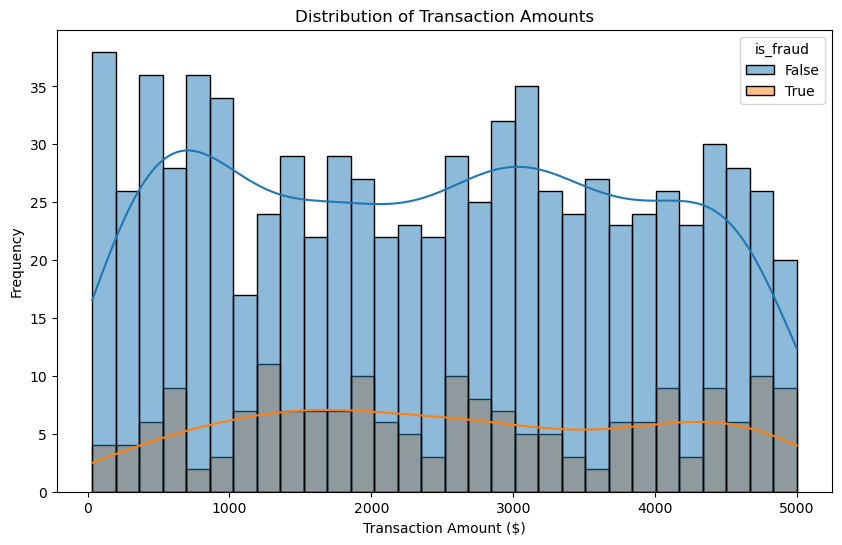

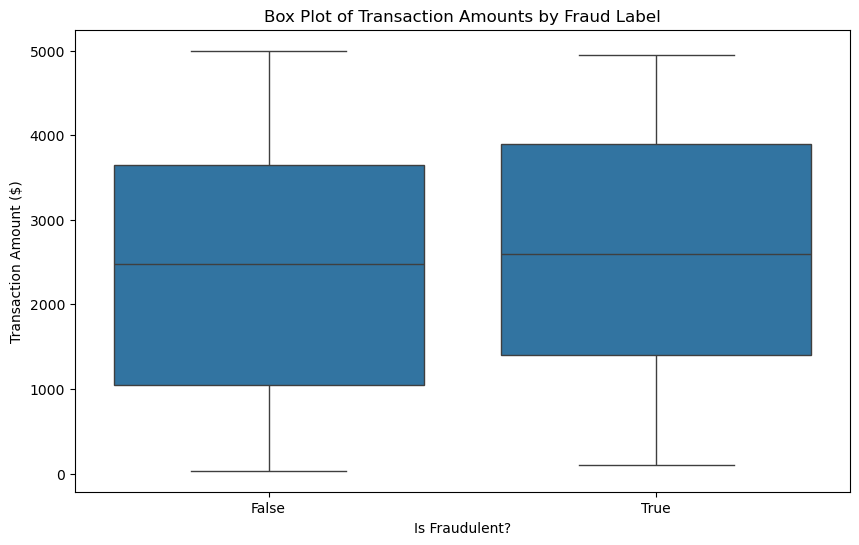

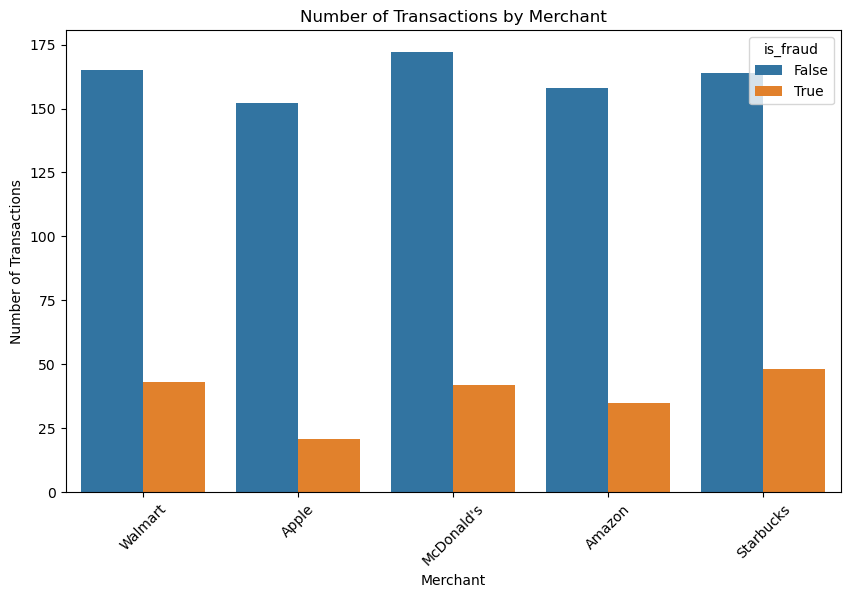

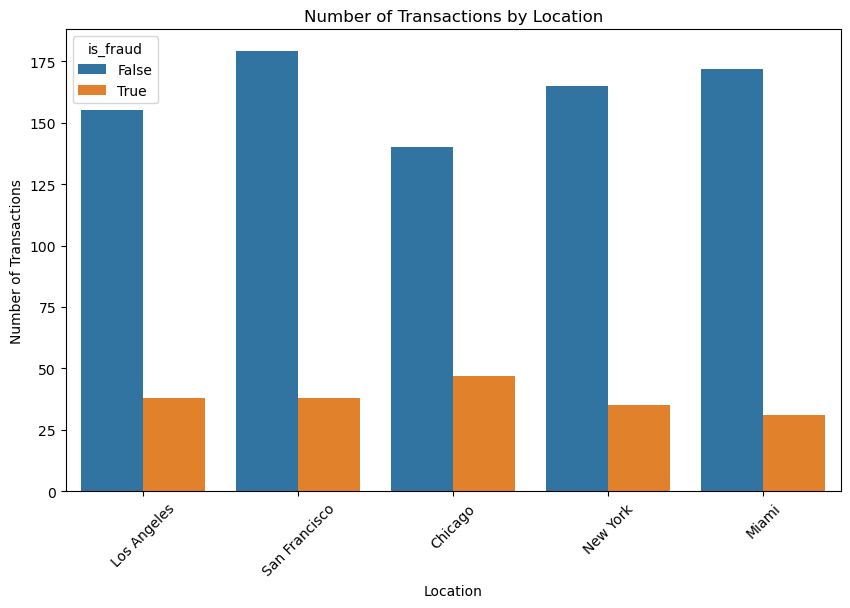

In [7]:
# Data Visualization
# Histogram of transaction amounts
plt.figure(figsize=(10, 6))
sns.histplot(data=transactions_df, x='transaction_amount', bins=30, kde=True, hue='is_fraud')
plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Frequency')
plt.show()

# Box plot of transaction amounts
plt.figure(figsize=(10, 6))
sns.boxplot(data=transactions_df, x='is_fraud', y='transaction_amount')
plt.title('Box Plot of Transaction Amounts by Fraud Label')
plt.xlabel('Is Fraudulent?')
plt.ylabel('Transaction Amount ($)')
plt.show()

# Bar plot of transactions by merchant
plt.figure(figsize=(10, 6))
sns.countplot(data=transactions_df, x='merchant', hue='is_fraud')
plt.title('Number of Transactions by Merchant')
plt.xlabel('Merchant')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.show()

# Bar plot of transactions by location
plt.figure(figsize=(10, 6))
sns.countplot(data=transactions_df, x='location', hue='is_fraud')
plt.title('Number of Transactions by Location')
plt.xlabel('Location')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.show()

# 3.2 Correlation Matrix

Correlation Matrix:
                    transaction_id  transaction_amount
transaction_id            1.000000           -0.024495
transaction_amount       -0.024495            1.000000


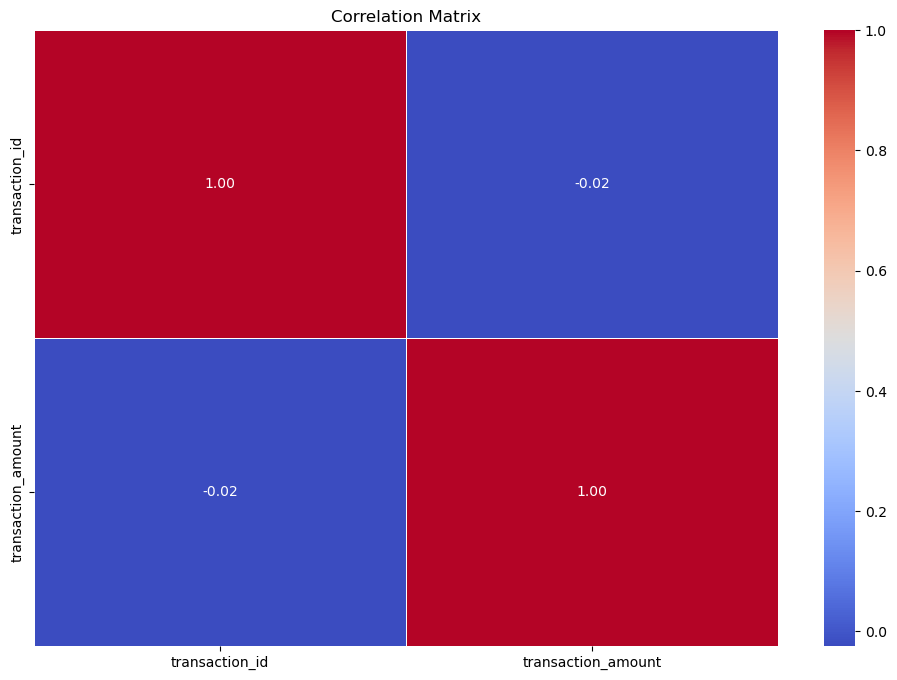

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric columns
numeric_df = transactions_df.select_dtypes(include=['number'])

# Compute the correlation matrix
correlation_matrix = numeric_df.corr()

# Display the correlation matrix
print("Correlation Matrix:")
print(correlation_matrix)

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


# 4.Model Comparison

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def compare_classifiers(data):
    # Split data into features and target variable
    X = data.drop(columns=['transaction_id', 'is_fraud'])
    y = data['is_fraud']
    
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Preprocessing pipeline
    numeric_features = ['transaction_amount']
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])

    categorical_features = ['merchant', 'location']
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    # Classifiers
    classifiers = {
        "Logistic Regression": LogisticRegression(),
        "SVM": SVC(),
        "Random Forest": RandomForestClassifier()
    }

    # Train and evaluate classifiers
    results = {}
    for name, clf in classifiers.items():
        clf_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        clf_pipeline.fit(X_train, y_train)
        y_pred = clf_pipeline.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        results[name] = accuracy

    return results

# Example usage:
# Load your dataset
data = pd.read_csv('financial_transactions.csv')

# Call compare_classifiers function
results = compare_classifiers(data)

# Print the results
print("Accuracy of Different Classifiers:")
for classifier, accuracy in results.items():
    print(f"{classifier}: {accuracy}")


Accuracy of Different Classifiers:
Logistic Regression: 0.81
SVM: 0.81
Random Forest: 0.725


# 4.1 Confusion Matrix Comparison

Accuracy of Different Classifiers:
Logistic Regression: 0.81
SVM: 0.81
Random Forest: 0.72


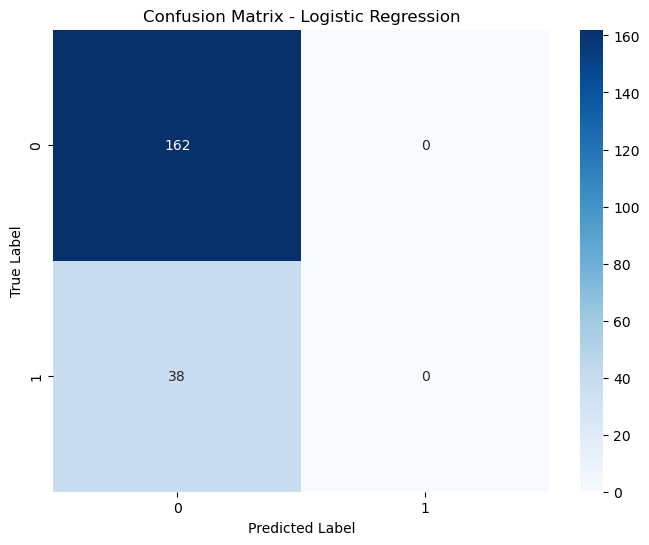

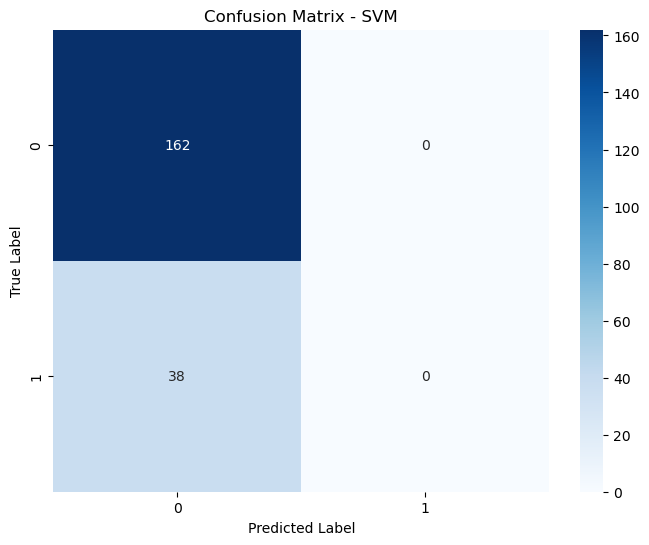

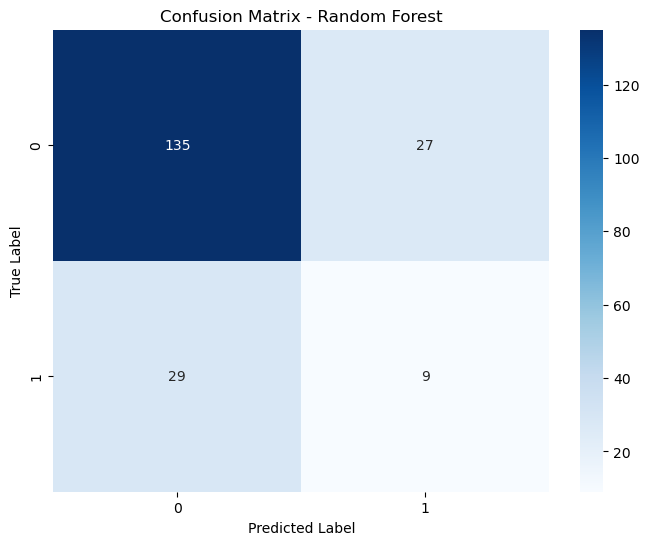

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def compare_classifiers(data):
    # Split data into features and target variable
    X = data.drop(columns=['transaction_id', 'is_fraud'])
    y = data['is_fraud']
    
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Preprocessing pipeline
    numeric_features = ['transaction_amount']
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])

    categorical_features = ['merchant', 'location']
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    # Classifiers
    classifiers = {
        "Logistic Regression": LogisticRegression(),
        "SVM": SVC(),
        "Random Forest": RandomForestClassifier()
    }

    # Train and evaluate classifiers
    results = {}
    confusion_matrices = {}
    for name, clf in classifiers.items():
        clf_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        clf_pipeline.fit(X_train, y_train)
        y_pred = clf_pipeline.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        results[name] = accuracy
        cm = confusion_matrix(y_test, y_pred)
        confusion_matrices[name] = cm

    return results, confusion_matrices

# Example usage:
# Load your dataset
data = pd.read_csv('financial_transactions.csv')

# Call compare_classifiers function
results, confusion_matrices = compare_classifiers(data)

# Print the results
print("Accuracy of Different Classifiers:")
for classifier, accuracy in results.items():
    print(f"{classifier}: {accuracy}")

# Plot the confusion matrices
for classifier, cm in confusion_matrices.items():
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {classifier}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()


# 4.2 ROC and AUC Comparison

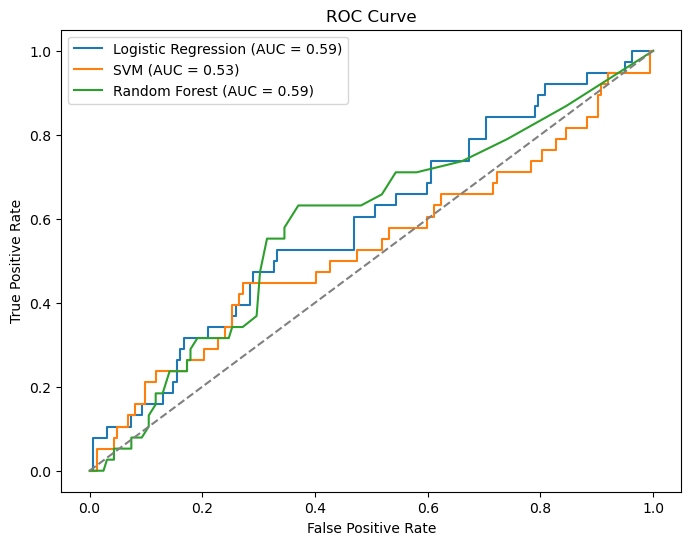

In [11]:
import pandas as pd                     # Import pandas for data manipulation
import matplotlib.pyplot as plt         # Import matplotlib for plotting ROC curves
from sklearn.metrics import roc_curve, roc_auc_score   # Metrics for ROC curve and AUC score
from sklearn.model_selection import train_test_split   # Utility to split dataset into train/test sets
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # Preprocessing tools for scaling and encoding
from sklearn.compose import ColumnTransformer          # Combine different preprocessing steps
from sklearn.pipeline import Pipeline                  # Build pipelines for preprocessing + model
from sklearn.linear_model import LogisticRegression    # Logistic Regression classifier
from sklearn.svm import SVC                            # Support Vector Machine classifier
from sklearn.ensemble import RandomForestClassifier    # Random Forest classifier

def compare_classifiers(data):
    # Separate features (X) and target variable (y)
    X = data.drop(columns=['transaction_id', 'is_fraud'])   # Drop ID and target column
    y = data['is_fraud']                                    # Target variable: fraud or not
    
    # Split dataset into training and testing sets (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Define preprocessing for numeric features
    numeric_features = ['transaction_amount']               # Numeric column
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())                        # Standardize numeric values
    ])

    # Define preprocessing for categorical features
    categorical_features = ['merchant', 'location']         # Categorical columns
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))  # One-hot encode categories
    ])

    # Combine numeric and categorical preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features), # Apply scaler to numeric
            ('cat', categorical_transformer, categorical_features) # Apply one-hot to categorical
        ])

    # Define classifiers to compare
    classifiers = {
        "Logistic Regression": LogisticRegression(),        # Logistic Regression model
        "SVM": SVC(probability=True),                       # Support Vector Machine with probability output
        "Random Forest": RandomForestClassifier()           # Random Forest model
    }

    # Dictionaries to store results
    results = {}       # Store ROC curve points
    roc_curves = {}    # Store ROC curve data
    auc_scores = {}    # Store AUC scores
    
    # Train and evaluate each classifier
    for name, clf in classifiers.items():
        # Build pipeline: preprocessing + classifier
        clf_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        clf_pipeline.fit(X_train, y_train)                  # Train model
        
        # Predict probabilities for test set
        y_pred_proba = clf_pipeline.predict_proba(X_test)[:, 1]   # Probability of fraud
        
        # Compute ROC curve
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba)       # False Positive Rate, True Positive Rate
        auc = roc_auc_score(y_test, y_pred_proba)           # Area Under Curve (AUC)
        
        # Store results
        results[name] = (fpr, tpr)
        roc_curves[name] = (fpr, tpr)
        auc_scores[name] = auc

    return results, auc_scores   # Return ROC curve data and AUC scores

# Example usage:
# Load dataset
data = pd.read_csv('financial_transactions.csv')

# Run comparison function
roc_curves, auc_scores = compare_classifiers(data)

# Plot ROC curves for all classifiers
plt.figure(figsize=(8, 6))
for classifier, (fpr, tpr) in roc_curves.items():
    plt.plot(fpr, tpr, label=f'{classifier} (AUC = {auc_scores[classifier]:.2f})')

# Plot diagonal line (random guess baseline)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')      # X-axis label
plt.ylabel('True Positive Rate')       # Y-axis label
plt.title('ROC Curve')                 # Plot title
plt.legend()                           # Show legend with classifier names and AUC
plt.show()                             # Display plot


# 5.Final Model For Deployment

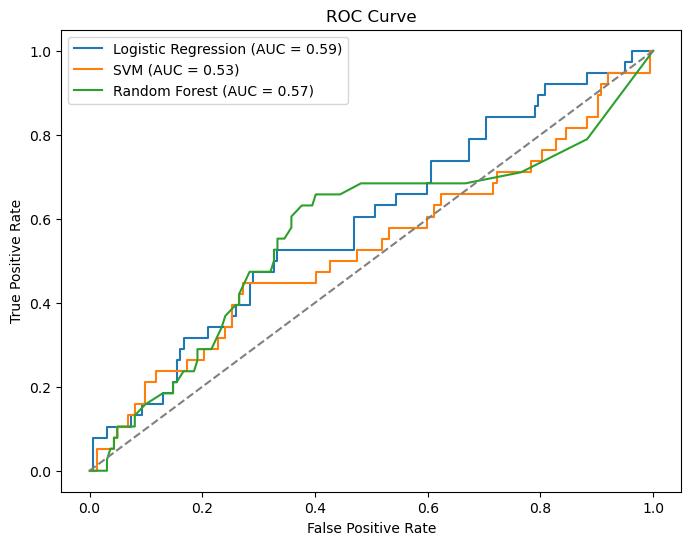

In [12]:
import pandas as pd                     # Pandas: load and manipulate tabular data
import matplotlib.pyplot as plt         # Matplotlib: visualize ROC curves
from sklearn.metrics import roc_curve, roc_auc_score   # Metrics: ROC curve points and AUC score
from sklearn.model_selection import train_test_split   # Split dataset into train/test sets
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # Scale numeric data, encode categorical data
from sklearn.compose import ColumnTransformer          # Apply different preprocessing to different columns
from sklearn.pipeline import Pipeline                  # Chain preprocessing + model into one workflow
from sklearn.linear_model import LogisticRegression    # Logistic Regression classifier
from sklearn.svm import SVC                            # Support Vector Machine classifier
from sklearn.ensemble import RandomForestClassifier    # Random Forest classifier

def compare_classifiers(data):
    # Purpose: Compare multiple classifiers (Logistic Regression, SVM, Random Forest)
    # on fraud detection using ROC curves and AUC scores.

    # Separate features (X) and target variable (y)
    X = data.drop(columns=['transaction_id', 'is_fraud'])   # Features: all columns except ID and target
    y = data['is_fraud']                                    # Target: fraud flag (1 = fraud, 0 = not fraud)
    
    # Split dataset into training and testing sets (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Define preprocessing for numeric features
    numeric_features = ['transaction_amount']               # Numeric column to scale
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())                        # Standardize values (mean=0, variance=1)
    ])

    # Define preprocessing for categorical features
    categorical_features = ['merchant', 'location']         # Categorical columns to encode
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))  # Convert categories into binary vectors
    ])

    # Combine numeric and categorical preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features), # Apply scaling to numeric features
            ('cat', categorical_transformer, categorical_features) # Apply one-hot encoding to categorical features
        ])

    # Define classifiers to compare
    classifiers = {
        "Logistic Regression": LogisticRegression(),        # Linear model for classification
        "SVM": SVC(probability=True),                       # Support Vector Machine with probability outputs
        "Random Forest": RandomForestClassifier()           # Ensemble of decision trees
    }

    # Dictionaries to store results
    results = {}       # Store ROC curve points (FPR, TPR)
    roc_curves = {}    # Store ROC curve data for plotting
    auc_scores = {}    # Store AUC scores (performance metric)
    
    # Train and evaluate each classifier
    for name, clf in classifiers.items():
        # Build pipeline: preprocessing + classifier
        clf_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        clf_pipeline.fit(X_train, y_train)                  # Train model on training data
        
        # Predict probabilities for test set
        y_pred_proba = clf_pipeline.predict_proba(X_test)[:, 1]   # Probability of fraud (class 1)
        
        # Compute ROC curve
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba)       # False Positive Rate, True Positive Rate
        auc = roc_auc_score(y_test, y_pred_proba)           # Area Under Curve (AUC) score
        
        # Store results
        results[name] = (fpr, tpr)
        roc_curves[name] = (fpr, tpr)
        auc_scores[name] = auc

    return results, auc_scores   # Return ROC curve data and AUC scores

# Example usage:
# Load dataset
data = pd.read_csv('financial_transactions.csv')   # Load financial transactions dataset

# Run comparison function
roc_curves, auc_scores = compare_classifiers(data) # Get ROC curves and AUC scores for classifiers

# Plot ROC curves for all classifiers
plt.figure(figsize=(8, 6))
for classifier, (fpr, tpr) in roc_curves.items():
    plt.plot(fpr, tpr, label=f'{classifier} (AUC = {auc_scores[classifier]:.2f})')

# Plot diagonal line (random guess baseline)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')   # Reference line for random guessing
plt.xlabel('False Positive Rate')      # X-axis label
plt.ylabel('True Positive Rate')       # Y-axis label
plt.title('ROC Curve')                 # Plot title
plt.legend()                           # Show legend with classifier names and AUC scores
plt.show()                             # Display plot


# 6.Sample Datas to Test the Model

In [13]:
## import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from datetime import datetime
import joblib

# 1. Load and preprocess data
data = pd.read_csv('financial_transactions.csv')   # Load dataset containing transaction records
data['transaction_time'] = pd.to_datetime(data['transaction_time'])   # Convert transaction time to datetime format
data['hour'] = data['transaction_time'].dt.hour    # Extract hour from transaction time
data['minute'] = data['transaction_time'].dt.minute # Extract minute
data['second'] = data['transaction_time'].dt.second # Extract second

# Define features (X) and target (y)
X = data[['transaction_amount', 'merchant', 'hour', 'minute', 'second', 'location']]  # Input features
y = data['is_fraud']   # Target variable (fraudulent or not)

# 2. Define preprocessing steps
numeric_features = ['transaction_amount', 'hour', 'minute', 'second']   # Numeric columns
categorical_features = ['merchant', 'location']                         # Categorical columns

# Scale numeric features (normalize values)
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Encode categorical features (convert text to numeric vectors)
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing for numeric + categorical features
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 3. Define model pipeline (handle class imbalance with class_weight='balanced')
model = Pipeline(steps=[
    ('preprocessor', preprocessor),   # Apply preprocessing
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000)) # Logistic Regression model
])

# 4. Train model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # Split dataset
model.fit(X_train, y_train)   # Train model on training data

# 5. Save the model for future use
joblib.dump(model, 'fraud_detection_model.pkl')   # Save trained model to file
print("Model trained and saved successfully.")

# 6. Function to test the model with user input
def predict_fraud():
    try:
        # Get user inputs for transaction details
        amount = float(input("Enter transaction amount: "))
        merchant = input("Enter merchant name: ").strip()
        time_str = input("Enter transaction time (YYYY-MM-DD HH:MM:SS): ").strip()
        time = datetime.strptime(time_str, '%Y-%m-%d %H:%M:%S')   # Convert input string to datetime
        hour = time.hour
        minute = time.minute
        second = time.second
        location = input("Enter transaction location: ").strip()

        # Create input DataFrame for prediction
        input_df = pd.DataFrame([{
            'transaction_amount': amount,
            'merchant': merchant,
            'hour': hour,
            'minute': minute,
            'second': second,
            'location': location
        }])

        # Load saved model
        model = joblib.load('fraud_detection_model.pkl')

        # Predict fraud probability
        prediction = model.predict(input_df)[0]             # Predicted class (0 = legitimate, 1 = fraud)
        probability = model.predict_proba(input_df)[0][1]   # Probability of fraud

        # Display result with confidence
        if prediction == 1:
            print(f"\n⚠️ The transaction is predicted to be **FRAUDULENT** with {probability:.2%} confidence.")
        else:
            print(f"\n✅ The transaction is predicted to be **LEGITIMATE** with {1 - probability:.2%} confidence.")

    except Exception as e:
        print("Error during prediction:", str(e))

# 7. Run prediction interactively
predict_fraud()


Model trained and saved successfully.


Enter transaction amount:  1878.955193
Enter merchant name:  Walmart
Enter transaction time (YYYY-MM-DD HH:MM:SS):  2024-03-15 20:43:31
Enter transaction location:  Los Angeles



⚠️ The transaction is predicted to be **FRAUDULENT** with 59.13% confidence.


In [14]:
import joblib

# Save the model as a joblib file
model = joblib.load('fraud_detection_model.pkl')


print("Model saved successfully as 'fraud_detection_model.joblib'")


Model saved successfully as 'fraud_detection_model.joblib'
